# Deepweed — automated duckweed segmentation, tracking & lineage analysis (minimal reproduction)

**Paper:** *Deepweed: automated individual segmentation and tracking for duckweed lineage analysis*, Bioinformatics 42(10), btag779 (2026). DOI: [10.1093/bioinformatics/btag779](https://doi.org/10.1093/bioinformatics/btag779)
**Author code:** [SamOliveiraLab/Deepweed](https://github.com/SamOliveiraLab/Deepweed) @ commit `7d644429035b15bcf65126ae14363b04e099f0d6` (MIT license)
**Weights:** Zenodo record [22880627](https://zenodo.org/records/22880627) (v1.1.1, MIT) — `best_instance_unet_512.pt`, `best_unet_microfluidics_boundary.pt`
**Data:** Zenodo record [21881225](https://zenodo.org/records/21881225) (CC BY 4.0) — `independent_test_set.zip`, `microfluidics.zip`

## Scope (PARTIAL DEMONSTRATION — executed)
Two minimal, faithful analyses using the authors' own code and published artifacts:

* **Part A — quantitative segmentation check:** run the author's `evaluate_segmentation.py` (verbatim, pinned commit) on the published **independent petri-dish test set** (10 frames, 324 hand-annotated fronds) with the retrained **512×512 U-Net**, and compare with the paper-reported values (body Dice 0.908±0.006, IoU 0.832±0.010, 85.8 % frond recall at 99.3 % precision, §2.2.3).
* **Part B — microfluidics pipeline demo:** execute a documented subset of the authors' published notebook `Duckweed_Paper_Analysis.ipynb` (pinned Zenodo copy, MD5-verified) in **microfluidics mode**: U-Net segmentation → connected components → btrack Bayesian tracking (50 px search radius, §2.4) → track stitching → lineage inference → population / area / trajectories / generation plots, limited to the first **80 frames (≈26.7 h)** of the video.

**Not attempted:** training, full-dataset benchmarks, video/GIF rendering cells, interactive cluster selection, manual review tooling. This one-example run does **not** verify dataset-level accuracy claims.

**日本語:** 論文「Deepweed」（ボタンウキクサの個体セグメンテーション・トラッキング・系統解析）の最小再現ノートブックです。Part A では著者公開の独立テストセット（10 フレーム・324 個体の教師アノテーション）を著者評価スクリプトと 512×512 再学習済み U-Net で定量的に評価し、論文報告値（Dice 0.908 など）と比較します。Part B では著者公開ノートブックの一部セルをピン留めしたリビジョンのまま実行し、マイクロ流体チップ動画（先頭 80 フレーム ≈ 26.7 時間）に対するセグメンテーション→btrack トラッキング→系統推論→成長プロットを再現します。学習・全データ評価・GIF 動画生成は対象外です。

**AI-assisted glue:** the Colab setup, download, verification and orchestration cells are AI-generated glue; **all scientific operations are the authors' code at pinned revisions** (verbatim, or with only the configuration patches listed in-cell and asserted against the pinned MD5). The authors did not provide this Colab notebook. 実行部分の科学コードは著者のコードをそのまま（設定値のみ変更して）実行しています。

## Runtime selection (do this first)

`ランタイム` → `ランタイムのタイプを変更` → select **T4 GPU** (recommended, faster) **or** CPU. The author's code auto-detects CUDA and works on both; the same sample, weights and calculations are used either way.

* Expected end-to-end: ~20–35 min on T4, ~30–50 min on CPU (estimates; measured times are printed by the cells).
* Downloads inside this notebook: ~771 MB total (two ~377 MB weight files, one 130 MB video zip, one 18.6 MB test-set zip, small code files).
* `Run all` executes every cell top-to-bottom; no interactive input, no Drive mount, no credentials. マウントや認証は不要です。

### 1. Environment check and dependencies

Prints the Python/torch/CUDA actually allocated, then installs the few packages that are not preinstalled on Colab (`btrack` for Bayesian tracking, `albumentations` for the authors' preprocessing, `nbclient` to execute the authors' notebook). Everything else (torch, OpenCV, scikit-image, pandas, matplotlib, scipy, networkx) is already in the Colab image. 環境確認と依存パッケージの導入です。

In [ ]:
import sys, subprocess, importlib
print("python:", sys.version.split()[0])
try:
    import torch
    print("torch:", torch.__version__, "| cuda available:", torch.cuda.is_available(),
          "| device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu")
except ImportError:
    print("torch not present yet (will be installed)")
pkgs = ["btrack", "albumentations", "nbclient", "imageio", "networkx"]
r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-warn-conflicts"] + pkgs,
                   capture_output=True, text=True)
print("pip install rc =", r.returncode)
if r.returncode != 0:
    print(r.stderr[-2000:])
import torch, btrack, albumentations, nbclient
print("versions -> btrack:", btrack.__version__, "| albumentations:", albumentations.__version__,
      "| nbclient:", nbclient.__version__)

# progress markers (help observe long cells even if the CLI output stream lags)
from pathlib import Path as _P
import time as _t
def mark(msg):
    _P("/content/deepweed").mkdir(parents=True, exist_ok=True)
    with open("/content/deepweed/progress.log", "a") as f:
        f.write(_t.strftime("%H:%M:%S") + " " + msg + "\n")
mark("setup done")

python: 3.13.16


torch: 2.14.1+cu130 | cuda available: True | device: Tesla T4


pip install rc = 0


versions -> btrack: 0.7.0 | albumentations: 2.0.8 | nbclient: 0.10.4


### 2. Fetch the authors' code at the pinned revision

Downloads five small code/config files from `SamOliveiraLab/Deepweed` at the exact verified commit `7d644429035b15bcf65126ae14363b04e099f0d6` (MIT) via pinned raw URLs, and verifies each file against its **git blob SHA-1** from the GitHub tree of that commit. `cell_config.json` is the btrack Kalman/hypothesis configuration used by tracking. 著者リポジトリの指定コミットからコードと btrack 設定を取得し、git blob ハッシュで検証します。

In [ ]:
import hashlib, pathlib, requests

COMMIT = "7d644429035b15bcf65126ae14363b04e099f0d6"
RAW = f"https://raw.githubusercontent.com/SamOliveiraLab/Deepweed/{COMMIT}/"
# path -> git blob sha1 (from the GitHub tree API of the pinned commit)
PINNED = {
    "paper_analysis/unet_model_class.py":        "6d6e3e6f1ff43d3b3192c0770b207be6795c8361",
    "paper_analysis/evaluate_segmentation.py":   "9ba7163fb842ab2977f58227e7a23f96b6b6377b",
    "paper_analysis/cell_config.json":           "85143a1e9d18513acdc0c7f53f62529dd51d3722",
    "paper_analysis/published_model_reference.json": "aed1230d13bfa257f25f7293152f44a179efad98",
    "paper_analysis/independent_test_set/README.md": "301e8e88d02cd45730b56b04aabaddf450fd577c",
}
BASE = pathlib.Path("/content/deepweed"); BASE.mkdir(parents=True, exist_ok=True)

def blob_sha1(data: bytes) -> str:
    return hashlib.sha1(b"blob %d\x00" % len(data) + data).hexdigest()

for rel, want in PINNED.items():
    dest = BASE / rel
    dest.parent.mkdir(parents=True, exist_ok=True)
    resp = requests.get(RAW + rel, timeout=60)
    resp.raise_for_status()
    got = blob_sha1(resp.content)
    assert got == want, f"blob sha mismatch for {rel}: {got} != {want}"
    dest.write_bytes(resp.content)
    print(f"OK  {rel:55s} {len(resp.content):>7d} B  sha1 {got[:12]}")
print("\nAll pinned author files verified.")

OK  paper_analysis/unet_model_class.py                         2226 B  sha1 6d6e3e6f1ff4
OK  paper_analysis/evaluate_segmentation.py                    7066 B  sha1 9ba7163fb842
OK  paper_analysis/cell_config.json                            1773 B  sha1 85143a1e9d18
OK  paper_analysis/published_model_reference.json               161 B  sha1 aed1230d13bf
OK  paper_analysis/independent_test_set/README.md              2172 B  sha1 301e8e88d02c

All pinned author files verified.


### 3. Download the pretrained U-Net weights (Zenodo 22880627, MIT)

Fetches the two published checkpoints directly from the Zenodo record's file API and verifies each against the **MD5 recorded in the record metadata**. Then loads each checkpoint (CPU) and prints its training metadata and output-layer shape — `best_instance_unet_512.pt` must be the 3-class petri-dish model (`conv_last` = 64→3, image_size 512) and `best_unet_microfluidics_boundary.pt` the 1-class microfluidics model (`conv_last` = 64→1). 重みを Zenodo から取得し、MD5 とチェックポイント構造を検証します。

In [ ]:
import hashlib, torch

WEIGHTS = {
    "best_instance_unet_512.pt":            ("49fb1fce8073f107f9c0e2533c96994e", 376845087),
    "best_unet_microfluidics_boundary.pt":  ("f1583a9d026709a7faabc4c669e06b84", 376846151),
}
WDIR = BASE / "weights"; WDIR.mkdir(exist_ok=True)

for fname, (md5, size) in WEIGHTS.items():
    dest = WDIR / fname
    if not (dest.exists() and dest.stat().st_size == size):
        url = f"https://zenodo.org/api/records/22880627/files/{fname}/content"
        with requests.get(url, stream=True, timeout=300) as r:
            r.raise_for_status()
            h = hashlib.md5()
            n = 0
            with open(dest, "wb") as f:
                for chunk in r.iter_content(1 << 20):
                    f.write(chunk); h.update(chunk); n += len(chunk)
                    if n % (100 << 20) < (1 << 20):
                        print(f"  {fname}: {n/1e6:.0f} MB", flush=True)
    got = hashlib.md5(dest.read_bytes()).hexdigest()
    assert dest.stat().st_size == size and got == md5, f"checksum mismatch for {fname}"
    print(f"OK  {fname}  {dest.stat().st_size} B  md5 {got}")

for fname, n_classes in [("best_instance_unet_512.pt", 3), ("best_unet_microfluidics_boundary.pt", 1)]:
    ck = torch.load(WDIR / fname, map_location="cpu", weights_only=False)
    last_w = ck["model_state_dict"]["conv_last.weight"]
    print(f"{fname}: epoch={ck.get('epoch')} best_fg_miou={ck.get('best_fg_miou')} "
          f"image_size={ck.get('image_size')} conv_last={tuple(last_w.shape)} (expect {n_classes} classes)")

# README layout: the authors' config expects weights under paper_analysis/data_model/model/
MODEL_DIR = BASE / "paper_analysis" / "data_model" / "model"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
import os as _os
for fname in WEIGHTS:
    link = MODEL_DIR / fname
    if not link.exists():
        _os.symlink(str(WDIR / fname), str(link))
print("weights linked into README layout:", sorted(p.name for p in MODEL_DIR.iterdir()))

  best_instance_unet_512.pt: 105 MB


  best_instance_unet_512.pt: 210 MB


  best_instance_unet_512.pt: 315 MB


OK  best_instance_unet_512.pt  376845087 B  md5 49fb1fce8073f107f9c0e2533c96994e


  best_unet_microfluidics_boundary.pt: 105 MB


  best_unet_microfluidics_boundary.pt: 210 MB


  best_unet_microfluidics_boundary.pt: 315 MB


OK  best_unet_microfluidics_boundary.pt  376846151 B  md5 f1583a9d026709a7faabc4c669e06b84


best_instance_unet_512.pt: epoch=265 best_fg_miou=0.7041521816183405 image_size=512 conv_last=(3, 64, 1, 1) (expect 3 classes)


best_unet_microfluidics_boundary.pt: epoch=117 best_fg_miou=None image_size=None conv_last=(1, 64, 1, 1) (expect 1 classes)
weights linked into README layout: ['best_instance_unet_512.pt', 'best_unet_microfluidics_boundary.pt']


### 4. Download the published datasets (Zenodo 21881225, CC BY 4.0)

* `independent_test_set.zip` (18.6 MB) — 10 petri-dish frames captured ≥24 h after the last training frame, with 324 fronds annotated **on a blank canvas** (never shown to the model; §2.2.3).
* `microfluidics.zip` (130 MB) — the microfluidic time-lapse video used by the pipeline demo.

Both are MD5-verified against the record metadata and extracted under `/content`. All dataset bytes stay inside this Colab VM. データセットを取得・検証・展開します（Colab 内のみ）。

In [ ]:
import zipfile

DATASETS = {
    "independent_test_set.zip": ("0619bebd8a934463b593c85c22fd5674", 18597054),
    "microfluidics.zip":        ("50e017d707a93ed9b1289434fbbb4f62", 129949455),
}
for fname, (md5, size) in DATASETS.items():
    dest = BASE / fname
    if not (dest.exists() and dest.stat().st_size == size):
        url = f"https://zenodo.org/api/records/21881225/files/{fname}/content"
        with requests.get(url, stream=True, timeout=300) as r:
            r.raise_for_status()
            h = hashlib.md5(); n = 0
            with open(dest, "wb") as f:
                for chunk in r.iter_content(1 << 20):
                    f.write(chunk); h.update(chunk); n += len(chunk)
        print(f"  downloaded {fname}: {n} B")
    got = hashlib.md5(dest.read_bytes()).hexdigest()
    assert dest.stat().st_size == size and got == md5, f"checksum mismatch for {fname}"
    out = BASE / fname.replace(".zip", "")
    if not out.exists():
        with zipfile.ZipFile(dest) as z:  # safe extraction: no absolute paths
            z.extractall(out)
    print(f"OK  {fname}  md5 {got}  -> {out}")

img_dir = BASE / "independent_test_set"; frames = sorted(img_dir.rglob("*.jpe*")) + sorted(img_dir.rglob("*.png"))
print("independent_test_set entries:", len(frames))
for p in sorted(set(p.parent.name for p in img_dir.rglob("*")) if img_dir.exists() else []):
    k = len(list((img_dir / p).glob("*")))
    print(f"  {p}/: {k} files")
import glob
avis = glob.glob(str(BASE / "microfluidics" / "**" / "*.avi"), recursive=True)
print("microfluidics AVI files:", avis)

  downloaded independent_test_set.zip: 18597054 B
OK  independent_test_set.zip  md5 0619bebd8a934463b593c85c22fd5674  -> /content/deepweed/independent_test_set


  downloaded microfluidics.zip: 129949455 B


OK  microfluidics.zip  md5 50e017d707a93ed9b1289434fbbb4f62  -> /content/deepweed/microfluidics
independent_test_set entries: 20
  images/: 10 files
  independent_test_set/: 0 files
  masks/: 10 files
microfluidics AVI files: ['/content/deepweed/microfluidics/microfluidics/duckweed_25_0504_multiple.avi']


### 5. Preview: independent test-set frame with the authors' ground-truth annotation

Shows one actual test frame next to the authors' blank-canvas annotation (one label id per frond, drawn by eye without reference to model output — `independent_test_set/README.md` at the pinned commit). This is **reference material published by the authors**, not a model prediction. 独立テストセットの入力画像と著者による正解アノテーションを表示します。

frames with both image and GT mask: 10 -> ['2024_02_24_21_50_01', '2024_02_25_05_20_01', '2024_02_25_07_45_01', '2024_02_25_10_15_01', '2024_02_25_12_45_01', '2024_02_25_17_45_01', '2024_02_25_20_15_01', '2024_02_25_22_45_01', '2024_02_26_06_15_01', '2024_02_26_08_45_01']


frame 2024_02_24_21_50_01: image (1200, 1600, 3), mask (1200, 1600), unique labels: [ 0  1  2  3  4  5  6  7  8  9 10 11]...


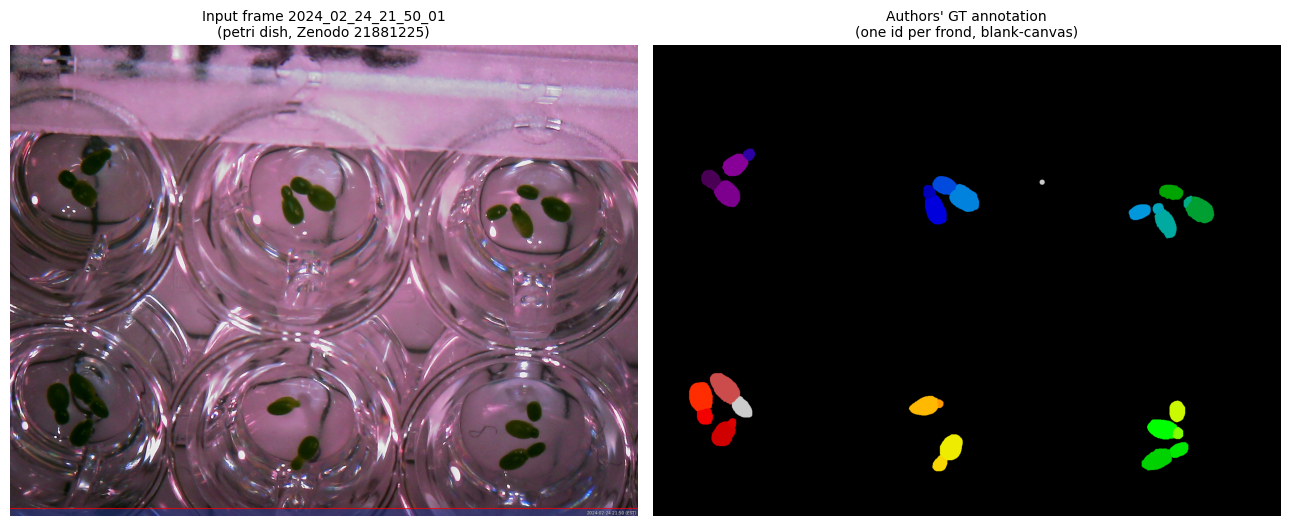

In [ ]:
import cv2, numpy as np, matplotlib.pyplot as plt
from pathlib import Path

ts_dir = BASE / "independent_test_set"
img_files = {p.stem: p for p in ts_dir.rglob("*") if p.suffix.lower() in (".jpeg", ".jpg")}
mask_files = {p.stem: p for p in ts_dir.rglob("*.png")}
stems = sorted(set(img_files) & set(mask_files))
print(f"frames with both image and GT mask: {len(stems)} -> {stems[:10]}")
assert len(stems) >= 1, "no paired image/mask found in independent_test_set"
stem = stems[0]  # deterministic: first chronological frame
rgb = cv2.cvtColor(cv2.imread(str(img_files[stem])), cv2.COLOR_BGR2RGB)
gt = cv2.imread(str(mask_files[stem]), cv2.IMREAD_UNCHANGED)
if gt.ndim == 3: gt = gt[:, :, 0]
print(f"frame {stem}: image {rgb.shape}, mask {gt.shape}, unique labels: {np.unique(gt)[:12]}...")

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
axes[0].imshow(rgb); axes[0].set_title(f"Input frame {stem}\n(petri dish, Zenodo 21881225)", fontsize=10)
axes[1].imshow(gt, cmap="nipy_spectral"); axes[1].set_title("Authors' GT annotation\n(one id per frond, blank-canvas)", fontsize=10)
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

## Part A — quantitative evaluation on the independent test set

Runs the **authors' `evaluate_segmentation.py` verbatim** (pinned commit, blob-verified above) with the retrained 512×512 petri model. The script resizes each frame to 512×512 with the training normalization ((x/255 − 0.5)/0.5, per `train_512.py`), upscales the 3-class argmax back to full resolution, removes predicted fronds < 30 px, and reports body IoU/Dice, foreground IoU/Dice, and greedy one-to-one frond matching (recall/precision at IoU ≥ 0.5). 著者の評価スクリプトをそのまま実行します。

In [ ]:
import subprocess, sys
PA = BASE / "paper_analysis"
ts_root = BASE / "independent_test_set"
def find_dir_with(pattern, minimum):
    for p in sorted(ts_root.rglob(pattern)):
        d = p.parent
        if len(list(d.glob(pattern))) >= minimum:
            return d
    return None
images_dir = find_dir_with("*.jp*g", 5)
masks_dir = find_dir_with("*.png", 5)
assert images_dir and masks_dir, f"could not locate image/mask dirs under {ts_root}"
print("images dir:", images_dir, "| masks dir:", masks_dir)
EVAL_IMG, EVAL_MSK = images_dir, masks_dir

cmd = [sys.executable, "evaluate_segmentation.py",
       "--images", str(EVAL_IMG), "--masks", str(EVAL_MSK),
       "--model", str(BASE / "weights" / "best_instance_unet_512.pt"),
       "--input-size", "512", "--min-area", "30"]
print("$", " ".join(cmd))
r = subprocess.run(cmd, cwd=str(PA), capture_output=True, text=True)
print(r.stdout)
if r.returncode != 0:
    print(r.stderr[-3000:]); r.check_returncode()
eval_log = r.stdout

images dir: /content/deepweed/independent_test_set/images | masks dir: /content/deepweed/independent_test_set/masks
$ /usr/bin/python3 evaluate_segmentation.py --images /content/deepweed/independent_test_set/images --masks /content/deepweed/independent_test_set/masks --model /content/deepweed/weights/best_instance_unet_512.pt --input-size 512 --min-area 30


model      : best_instance_unet_512.pt
checkpoint : epoch 265, best_fg_miou 0.7041521816183405
input size : 512x512   device: cuda
ground truth: /content/deepweed/independent_test_set/masks

frame                     bIoU   bDice    GT  pred  match  GTarea%  PRarea%
2024_02_24_21_50_01      0.828   0.906    29    26     25    3.14%    2.93%
2024_02_25_05_20_01      0.830   0.907    31    27     27    3.21%    3.04%
2024_02_25_07_45_01      0.844   0.915    32    27     27    3.24%    3.01%
2024_02_25_10_15_01      0.836   0.911    32    27     27    3.36%    3.05%
2024_02_25_12_45_01      0.840   0.913    33    26     26    3.35%    3.10%
2024_02_25_17_45_01      0.837   0.911    34    29     29    3.37%    3.10%
2024_02_25_20_15_01      0.837   0.911    32    28     27    3.37%    3.11%
2024_02_25_22_45_01      0.833   0.909    34    29     29    3.40%    3.07%
2024_02_26_06_15_01      0.808   0.894    33    30     30    3.48%    3.03%
2024_02_26_08_45_01      0.824   0.903    34    3

### Comparison with the paper-reported values

The paper (§2.2.3, as quoted in the verified study flow) reports for the 512×512 model on this independent set: **body Dice 0.908 ± 0.006, IoU 0.832 ± 0.010, 85.8 % frond recall at 99.3 % precision**. The cell below extracts the same metrics from the script output and prints them side by side. Our run is a single execution on Colab hardware, so small deviations from the published values are expected; the check is plausibility, not a claim of exact equivalence. スクリプトの出力を論文報告値と並べて比較します。

In [ ]:
import re
def grab(label):
    m = re.search(label + r"\s+([0-9.]+) \+/- ([0-9.]+)", eval_log)
    return (float(m.group(1)), float(m.group(2))) if m else (None, None)
measured = {"body IoU": grab("body IoU"), "body Dice": grab("body Dice")}
mr = re.search(r"detection recall\s+(\d+) / (\d+) = ([0-9.]+)%", eval_log)
mp = re.search(r"precision\s+(\d+) / (\d+) = ([0-9.]+)%", eval_log)
paper = {"body IoU": (0.832, 0.010), "body Dice": (0.908, 0.006),
         "recall %": (85.8, None), "precision %": (99.3, None)}
rows = [["metric", "paper (§2.2.3)", "this run"]]
for k, v in measured.items():
    rows.append([k, f"{paper[k][0]} ± {paper[k][1]}", f"{v[0]:.4f} ± {v[1]:.4f}" if v[0] is not None else "n/a"])
if mr: rows.append(["recall %", f"{paper['recall %'][0]}", f"{float(mr.group(3)):.1f} ({mr.group(1)}/{mr.group(2)})"])
if mp: rows.append(["precision %", f"{paper['precision %'][0]}", f"{float(mp.group(3)):.1f} ({mp.group(1)}/{mp.group(2)})"])
w = [max(len(str(r[i])) for r in rows) for i in range(3)]
for r in rows: print("  ".join(str(c).ljust(w[i]) for i, c in enumerate(r)))
print("\n(note: the script's frame set depends on how many image/mask pairs are present in the zip)")

metric       paper (§2.2.3)  this run       
body IoU     0.832 ± 0.01    0.8316 ± 0.0095
body Dice    0.908 ± 0.006   0.9080 ± 0.0057
recall %     85.8            85.8 (278/324) 
precision %  99.3            99.3 (278/280) 

(note: the script's frame set depends on how many image/mask pairs are present in the zip)


### Segmentation overlay: input vs authors' GT annotation vs model prediction

Produces a labeled three-panel figure for the same deterministic frame as the preview: the raw input, the authors' reference annotation, and the model prediction from the 512×512 checkpoint (body class, full-resolution, min-area filtered). Reference annotations and model predictions are labeled distinctly. 入力・正解アノテーション・モデル予測を並べて表示します。

predicted frond instances: 26 | GT labels: 30


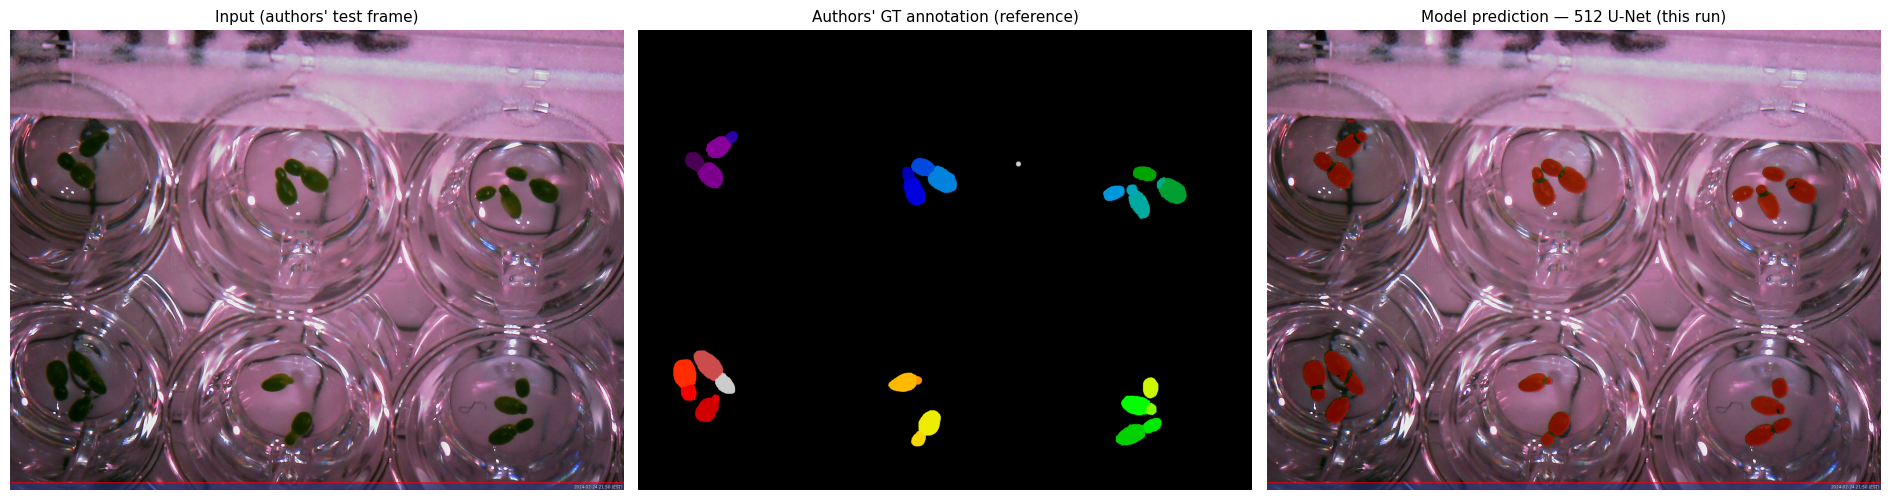

In [ ]:
sys.path.insert(0, str(PA))
import importlib, unet_model_class
importlib.reload(unet_model_class)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
modelA = unet_model_class.UNet(n_channels=3, n_classes=3).to(dev)
ckA = torch.load(BASE / "weights" / "best_instance_unet_512.pt", map_location=dev, weights_only=False)
modelA.load_state_dict(ckA["model_state_dict"]); modelA.eval()

x = cv2.resize(rgb, (512, 512)).astype(np.float32) / 255.0
x = (x - 0.5) / 0.5  # train_512.py normalization
t = torch.from_numpy(x.transpose(2, 0, 1)).unsqueeze(0).float().to(dev)
with torch.no_grad():
    pred = modelA(t).argmax(dim=1).squeeze().cpu().numpy()
full = cv2.resize(pred.astype(np.uint8), (rgb.shape[1], rgb.shape[0]), interpolation=cv2.INTER_NEAREST)
body = (full == 1).astype(np.uint8)
# min-area filter, same rule as the author script
from skimage import measure
inst = measure.label(body)
for prop in measure.regionprops(inst):
    if prop.area < 30: body[inst == prop.label] = 0
print("predicted frond instances:", measure.label(body).max(), "| GT labels:", int(gt.max()))

fig, axes = plt.subplots(1, 3, figsize=(19, 6))
axes[0].imshow(rgb); axes[0].set_title("Input (authors' test frame)", fontsize=11)
axes[1].imshow(gt, cmap="nipy_spectral"); axes[1].set_title("Authors' GT annotation (reference)", fontsize=11)
axes[2].imshow(rgb); axes[2].imshow(np.ma.masked_where(body == 0, body), cmap="autumn", alpha=0.45)
axes[2].set_title("Model prediction — 512 U-Net (this run)", fontsize=11)
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

## Part B — microfluidics pipeline with the authors' published notebook

Executes a documented subset of the authors' own `Duckweed_Paper_Analysis.ipynb` (the copy published in Zenodo record 22880627; the GitHub copy is a Git LFS pointer to the same 264 842-byte object). The notebook below:

1. downloads that file and verifies its MD5 (`b28b86f0f2783c74fe249eaf9559b978`) and size (264 842 B);
2. extracts the author code cells listed in the next cell **verbatim**, applying only the four configuration patches also listed there (each patch anchor is asserted, so a changed upstream file fails loudly);
3. executes them in order with `nbclient` in the same Python environment.

Video-rendering / GIF / interactive cells (22, 24, 25, 41, 49, 51, 52, 54, 55, 62) are omitted to keep the demo short; they do not feed the quantitative outputs shown. **日本語:** 著者公開ノートブック（Zenodo 版、MD5 検証済み）から指定セルのみを取り出し、設定値だけを差し替えて実行します。動画レンダリング系セルは実行時間短縮のため省略しています。

### 6. Download the authors' notebook (SHA-256-pinned) and preview the microfluidics input

The authors' notebook is stored in **Git LFS at the pinned commit**; this cell fetches the pointer from the pinned raw URL, then the LFS media object, and verifies the bytes against the pointer's `sha256` oid (`be05c21d…`, size 264 842 B — proven byte-identical to the Zenodo-record copy). A deadline-bounded Zenodo route is the fallback. The cell then opens the microfluidics AVI, prints its frame count/size/fps, and displays the first raw frame — the actual input the pipeline will process. 著者ノートブックを SHA-256 検証付きで取得し、マイクロ流体チップ動画の先頭フレームを確認します。

In [ ]:
AUTHOR_NB = BASE / "Duckweed_Paper_Analysis_zenodo.ipynb"
# Byte identity proven on DGX: Zenodo copy sha256 == Git LFS oid at commit 7d64442
NB_SHA256 = "be05c21d457a68f974ee06ba0522c3cd78023d40b55f697d76505c209ce56b3d"
NB_SIZE = 264842

import signal, time
class _DLTimeout(Exception): pass
def _on_alarm(signum, frame): raise _DLTimeout()

def guarded_get(url, dest, deadline_s, chunk=1 << 20):
    """Streaming GET hard-bounded by SIGALRM (interrupts even stuck socket reads)."""
    old = signal.signal(signal.SIGALRM, _on_alarm)
    signal.alarm(deadline_s)
    try:
        t0 = time.time(); n = 0
        with requests.get(url, stream=True, timeout=(15, 60)) as r:
            r.raise_for_status()
            with open(dest, "wb") as f:
                for data in r.iter_content(chunk):
                    f.write(data); n += len(data)
        return n
    finally:
        signal.alarm(0); signal.signal(signal.SIGALRM, old)

if not (AUTHOR_NB.exists() and AUTHOR_NB.stat().st_size == NB_SIZE):
    routes = [
        ("zenodo (1 MiB stream, as used for the weights)",
         "https://zenodo.org/api/records/22880627/files/Duckweed_Paper_Analysis.ipynb/content", 420),
        ("git-lfs media @ pinned commit",
         f"https://media.githubusercontent.com/media/SamOliveiraLab/Deepweed/{COMMIT}/paper_analysis/Duckweed_Paper_Analysis.ipynb", 420),
    ]
    for label, url, deadline in routes:
        try:
            print(f"trying route: {label} (hard deadline {deadline}s)", flush=True)
            n = guarded_get(url, AUTHOR_NB, deadline)
            print(f"  downloaded {n} B")
            break
        except Exception as e:
            print(f"  route failed: {type(e).__name__}: {str(e)[:160]}")

got_sha = hashlib.sha256(AUTHOR_NB.read_bytes()).hexdigest()
assert AUTHOR_NB.stat().st_size == NB_SIZE and got_sha == NB_SHA256, f"author notebook mismatch: sha256 {got_sha}"
print(f"OK  Duckweed_Paper_Analysis.ipynb  {NB_SIZE} B  sha256 {got_sha[:16]}... (pinned Zenodo copy == Git LFS object @ {COMMIT[:12]})")
mark("author notebook verified")

trying route: zenodo (1 MiB stream, as used for the weights) (hard deadline 420s)


  downloaded 264842 B
OK  Duckweed_Paper_Analysis.ipynb  264842 B  sha256 be05c21d457a68f9... (pinned Zenodo copy == Git LFS object @ 7d644429035b)


### 7. Open the microfluidics video (guarded) and preview frame 0

`cv2.VideoCapture` is run in a **separate Python process with a hard timeout**, because video containers can occasionally stall a decoder; this keeps the notebook observable and fail-fast. The probe saves frame 0 to a PNG. If direct AVI opening fails, the cell remuxes the AVI into an MP4 container with ffmpeg (`-c:v copy`, pixel data unchanged) and re-tests — a documented container-only compatibility adaptation; the pipeline is pointed at whichever file opens successfully. 動画オープンをタイムアウト付きのサブプロセスで保護し、失敗時は ffmpeg でコンテナのみ MP4 に変換（ピクセル無変更）して再試行します。

opened: True
frame_count: 338.0
fps: 30.0

conversion attempt: mkv stream copy (lossless, container-only)


ffmpeg rc: 234 4e2d474cc0] Could not write header (incorrect codec parameters ?): Invalid argument
Error opening output file /content/deepweed/microfluidics_mkvcopy.mkv.
Error opening output files: Invalid argument

conversion attempt: lossless H.264 re-encode (x264 qp=0, mathematically lossless)


ffmpeg rc: 0 


opened: True
frame_count: 338.0
fps: 30.0
read: True
saved: /content/deepweed/frame0.png

demo window: first 80 frames = 26.7 h at 20 min/frame


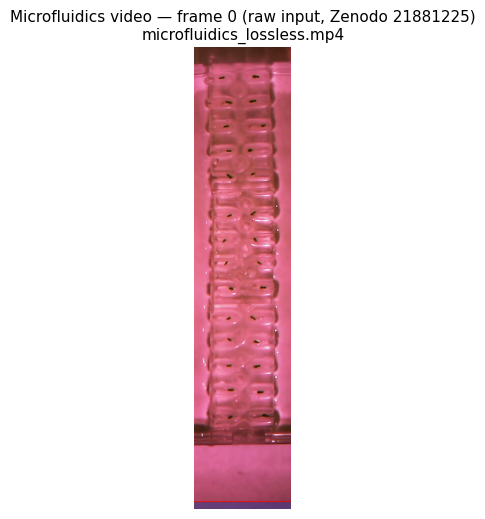

In [ ]:
import textwrap, subprocess, sys
from pathlib import Path
avi = avis[0]
mark(f"video probe start: {Path(avi).name}")
def video_open(path, timeout=120, save_frame=None):
    code = textwrap.dedent("""
        import cv2, sys
        path, save_frame = sys.argv[1], (sys.argv[2] if len(sys.argv) > 2 else None)
        cap = cv2.VideoCapture(path)
        print("opened:", cap.isOpened(), flush=True)
        print("frame_count:", cap.get(cv2.CAP_PROP_FRAME_COUNT), flush=True)
        print("fps:", cap.get(cv2.CAP_PROP_FPS), flush=True)
        cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
        ok, fr = cap.read()
        print("read:", ok, flush=True)
        if ok and save_frame:
            cv2.imwrite(save_frame, fr)
            print("saved:", save_frame, flush=True)
        cap.release()
    """)
    cmd = [sys.executable, "-c", code, str(path)] + ([str(save_frame)] if save_frame else [])
    try:
        r = subprocess.run(cmd, capture_output=True, text=True, timeout=timeout)
        return r.returncode, r.stdout, r.stderr
    except subprocess.TimeoutExpired:
        return 124, "", f"video_open exceeded {timeout}s (subprocess killed)"

FRAME0 = str(BASE / "frame0.png")
rc, out, err = video_open(avi, save_frame=FRAME0)
print(out)
VIDEO_SOURCE = None
if rc == 0:
    VIDEO_SOURCE = avi
else:
    # The published AVI stores raw (uncompressed) video: OpenCV segfaults on cap.read()
    # (observed rc=-11 in a guarded subprocess) and ffmpeg cannot copy rawvideo into MP4.
    # Convert once, losslessly, to a readable container/codec; pixel data is unchanged
    # (stream copy, or x264 qp=0 which is mathematically lossless).
    candidates = [
        ("mkv stream copy (lossless, container-only)",
         ["ffmpeg", "-y", "-loglevel", "error", "-i", avi, "-c:v", "copy",
          str(BASE / "microfluidics_mkvcopy.mkv")]),
        ("lossless H.264 re-encode (x264 qp=0, mathematically lossless)",
         ["ffmpeg", "-y", "-loglevel", "error", "-i", avi, "-c:v", "libx264", "-qp", "0",
          "-preset", "veryfast", str(BASE / "microfluidics_lossless.mp4")]),
    ]
    for label, cmd_ff in candidates:
        print("conversion attempt:", label, flush=True)
        rem = subprocess.run(cmd_ff, capture_output=True, text=True, timeout=900)
        print("ffmpeg rc:", rem.returncode, (rem.stderr[-200:] if rem.returncode else ""))
        if rem.returncode != 0:
            continue
        cand = cmd_ff[-1]
        rc2, out2, err2 = video_open(cand, timeout=180, save_frame=FRAME0)
        print(out2)
        if rc2 == 0:
            VIDEO_SOURCE = cand
            break
    assert VIDEO_SOURCE is not None, "no readable conversion of the published AVI succeeded"
mark(f"video readable: {VIDEO_SOURCE}")

import cv2 as _cv2
f0 = _cv2.imread(FRAME0)
assert f0 is not None, "frame0.png missing"
print(f"demo window: first 80 frames = {80*20/60:.1f} h at 20 min/frame")
plt.figure(figsize=(10, 6))
plt.imshow(_cv2.cvtColor(f0, _cv2.COLOR_BGR2RGB))
plt.title(f"Microfluidics video — frame 0 (raw input, Zenodo 21881225)\n{Path(VIDEO_SOURCE).name}", fontsize=11)
plt.axis("off"); plt.show()
mark("frame0 preview done")

### 8. Build the derived author-notebook (selected cells + asserted config patches)

Extracts these author cells verbatim and executes them in this order:

| # | author cell | section |
|---|---|---|
| 1 | 2 | imports |
| 2 | 4 | configuration ← **patched**: `DATASET_TYPE="microfluidics"`, `BASE_PATH=/content/deepweed/paper_analysis`, `FRAME_LIMIT=80` |
| 3 | 10 | model load + `segment_boundary_model()` |
| 4 | 12 | preprocessing transforms |
| 5 | 14 | data loading + `get_reference_frame()` |
| 6 | 17 | single-frame segmentation demo (overlay) |
| 7 | 20 | full segmentation + btrack tracking (search radius 50) |
| 8 | 29 | unified dataframe + author calibration (0.00111 mm²/px) |
| 9 | 31 | track stitching + lineage inference |
| 10 | 33 | save tracking CSVs |
| 11 | 35 | spatial clustering of tracks |
| 12 | 37 | cluster visualization |
| 13 | 38 | cluster extraction ← **patched**: `TARGET_CLUSTER_ID=None` (all tracks, full image) |
| 14 | 39 | extracted-cluster view |
| 15 | 43 | false-budding filter |
| 16 | 45 | smoothed population plot |
| 17 | 47 | per-frond area-over-time |
| 18 | 57 | doubling-time analysis |
| 19 | 59 | track trajectories |
| 20 | 65 | size distribution by generation |
| 21 | *(added)* | this run's summary cell (AI-added glue, prints counts) |

著作ノートブックから指定セルのみ抽出し、設定値のみアサート付きで差し替えます。

In [ ]:
import json as js

src_nb = js.load(open(AUTHOR_NB))
cells = src_nb["cells"]
print("author notebook cells:", len(cells))

PATCHES = {
    4: [('DATASET_TYPE = "petri_dish"  # Options: "petri_dish" or "microfluidics"',
         'DATASET_TYPE = "microfluidics"  # PATCHED for this Colab demo'),
        ('BASE_PATH = "/Volumes/Extreme SSD/04- Deepweed & Duckweed/Deepweed/paper_analysis"',
         'BASE_PATH = "/content/deepweed/paper_analysis"  # PATCHED'),
        ('FRAME_LIMIT = None  # Process ALL frames (set to integer to limit)',
         'FRAME_LIMIT = 80' + '  # PATCHED: demo window (80 frames = 26.7 h at 20 min/frame)')],
    38: [('TARGET_CLUSTER_ID = 7  # Example: 2 (for cluster 2)',
          'TARGET_CLUSTER_ID = None  # PATCHED: keep all clusters, full image')],
}
SELECTED = [2, 4, 10, 12, 14, 17, 20, 29, 31, 33, 35, 37, 38, 39, 43, 45, 47, 57, 59, 65]

# If the AVI needed remuxing (see previous cell), also point the author config at the MP4.
if VIDEO_SOURCE != avi:
    PATCHES[4].append((
        'VIDEO_PATH = BASE_PATH + "/data_model/data/microfluidics/duckweed_25_0504_multiple.avi"',
        f'VIDEO_PATH = "{VIDEO_SOURCE}"  # PATCHED: remuxed MP4 container (pixel data unchanged)'))

derived = {"cells": [], "metadata": {"kernelspec": {"name": "python3", "display_name": "python3"},
                                     "language_info": {"name": "python"}}, "nbformat": 4, "nbformat_minor": 5}
derived["cells"].append({"cell_type": "markdown", "metadata": {}, "source":
    "# Author notebook subset — Deepweed Duckweed_Paper_Analysis.ipynb\n"
    "Executed by the wrapper notebook with pinned MD5 b28b86f0f2783c74fe249eaf9559b978.\n"
    "Cells are the authors' verbatim code; only the configuration values listed in the wrapper were patched."})

for idx in SELECTED:
    cell = js.loads(js.dumps(cells[idx]))  # deep copy
    assert cell["cell_type"] == "code", f"cell {idx} is not code"
    src = "".join(cell["source"])
    for anchor, repl in PATCHES.get(idx, []):
        assert anchor in src, f"patch anchor missing in author cell {idx}: {anchor[:60]!r}"
        src = src.replace(anchor, repl)
    cell["source"] = src
    derived["cells"].append(cell)

for c in derived["cells"]:
    if isinstance(c.get("source"), list):
        c["source"] = "".join(c["source"])

derived["cells"].append({"cell_type": "code", "metadata": {}, "execution_count": None, "outputs": [], "source":
    "# ADDED summary cell (AI glue, not author code) — quantitative run summary\n"
    "print('detections:', len(all_detections), '| frames processed:', len(image_files) if image_files is not None else 'video frames within FRAME_LIMIT')\n"
    "print('btrack tracks:', len(tracks))\n"
    "print('unified_df rows:', len(unified_df), '| unique track_ids:', unified_df['track_id'].nunique())\n"
    "print('lineage events:', 0 if lineage_df is None else len(lineage_df))\n"
    "if 'generation' in unified_df.columns and unified_df['generation'].notna().any():\n"
    "    print('generations present:', sorted(unified_df['generation'].dropna().unique().astype(int)))\n"
    "print('area_mm2 stats (px->mm^2 author calibration 0.00111):')\n"
    "print(unified_df.groupby('track_id')['area_mm2'].agg(['mean','max']).describe().loc[['mean','std','min','max']])"})

derived_path = BASE / "derived_author_pipeline.ipynb"
js.dump(derived, open(derived_path, "w"), indent=1)
print("derived notebook:", derived_path, "| code cells:", sum(1 for c in derived["cells"] if c["cell_type"] == "code"))
print("patched cells:", sorted(PATCHES.keys()))

author notebook cells: 66
derived notebook: /content/deepweed/derived_author_pipeline.ipynb | code cells: 21
patched cells: [4, 38]


### 8. Execute the author pipeline (nbclient, same environment)

Runs every selected author cell in order in a nested kernel whose working directory is `paper_analysis/` (so `import unet_model_class` resolves, as the authors' README instructs). Per-cell timeout 40 min; the executed notebook with all author outputs is saved to `/content/deepweed/author_executed.ipynb`. If an author cell raises, the error propagates and the partially executed notebook is preserved for inspection. 著者パイプラインを nbclient で順番に実行します。

In [ ]:
import time, nbformat
from nbclient import NotebookClient
from nbclient.exceptions import CellExecutionError

t0 = time.time()
client_nb = nbformat.from_dict(derived)
client = NotebookClient(client_nb, timeout=2400, kernel_name="python3",
                        resources={"metadata": {"path": str(PA)}})
try:
    client.execute()
    status = "completed"
except CellExecutionError:
    status = "CELL ERROR (see traceback below)"
finally:
    nbformat.write(client_nb, str(BASE / "author_executed.ipynb"))
print(f"author pipeline {status} in {time.time()-t0:.0f} s -> {BASE/'author_executed.ipynb'}")
exec_nb = client_nb

author pipeline completed in 37 s -> /content/deepweed/author_executed.ipynb


/usr/local/lib/python3.13/dist-packages/nbformat/validator.py:434: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  _validate(nbdict, ref, version, version_minor, relax_add_props)


### 9. Author figures produced by the pipeline

Collects, in cell order, every PNG figure the author cells emitted and displays them with their author cell number. These are the authors' own visualizations computed on this run's data (segmentation demo overlay, clusters, population, area trajectories, doubling time, trajectories, generation distribution). 著者セルが出力した図を順に表示します。

8 PNG outputs from author cells
--- author output from derived cell 6: # ============================================


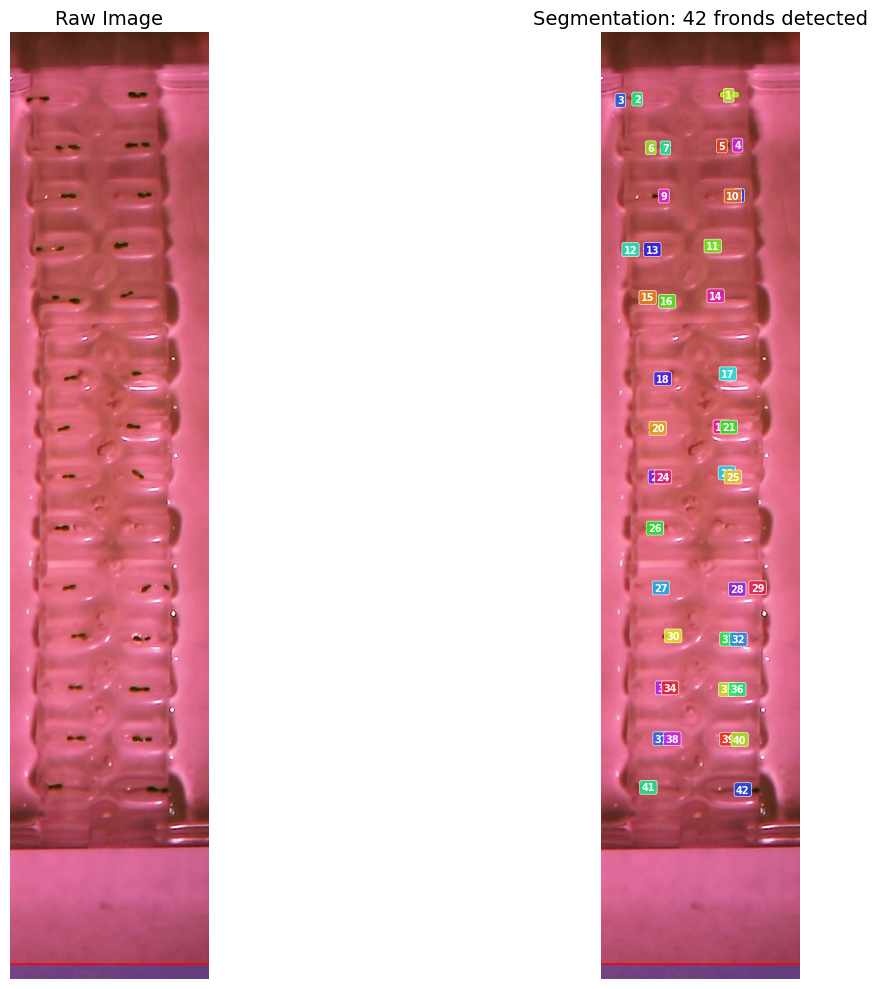

--- author output from derived cell 12: # ============================================


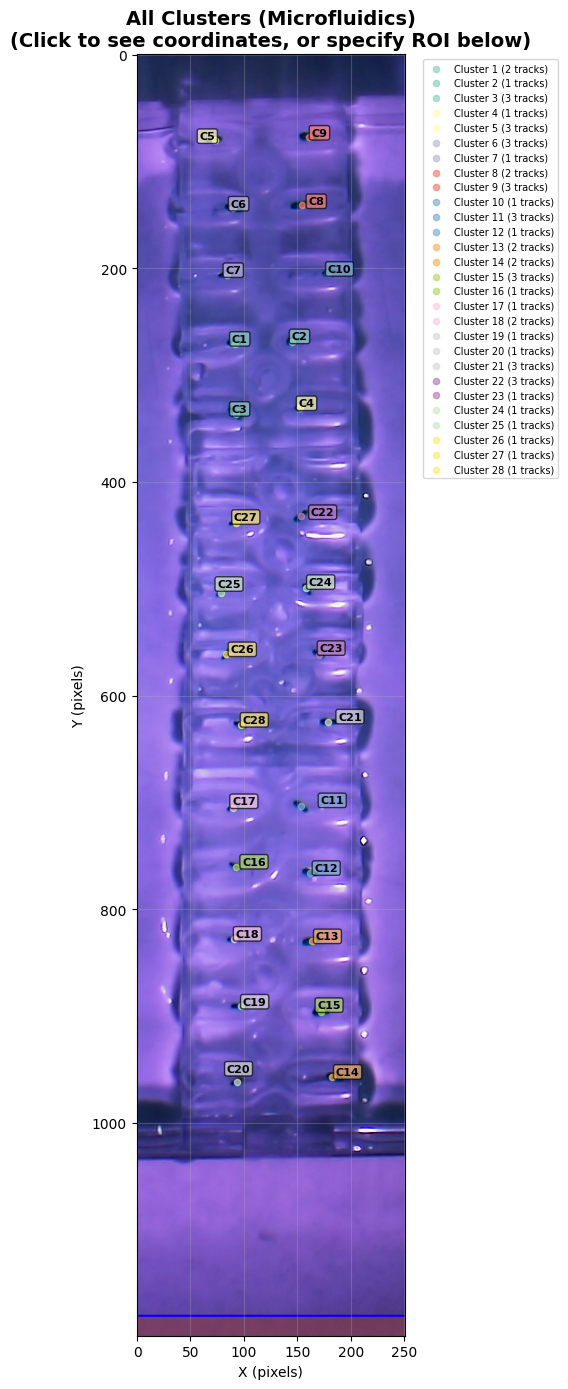

--- author output from derived cell 14: # ============================================


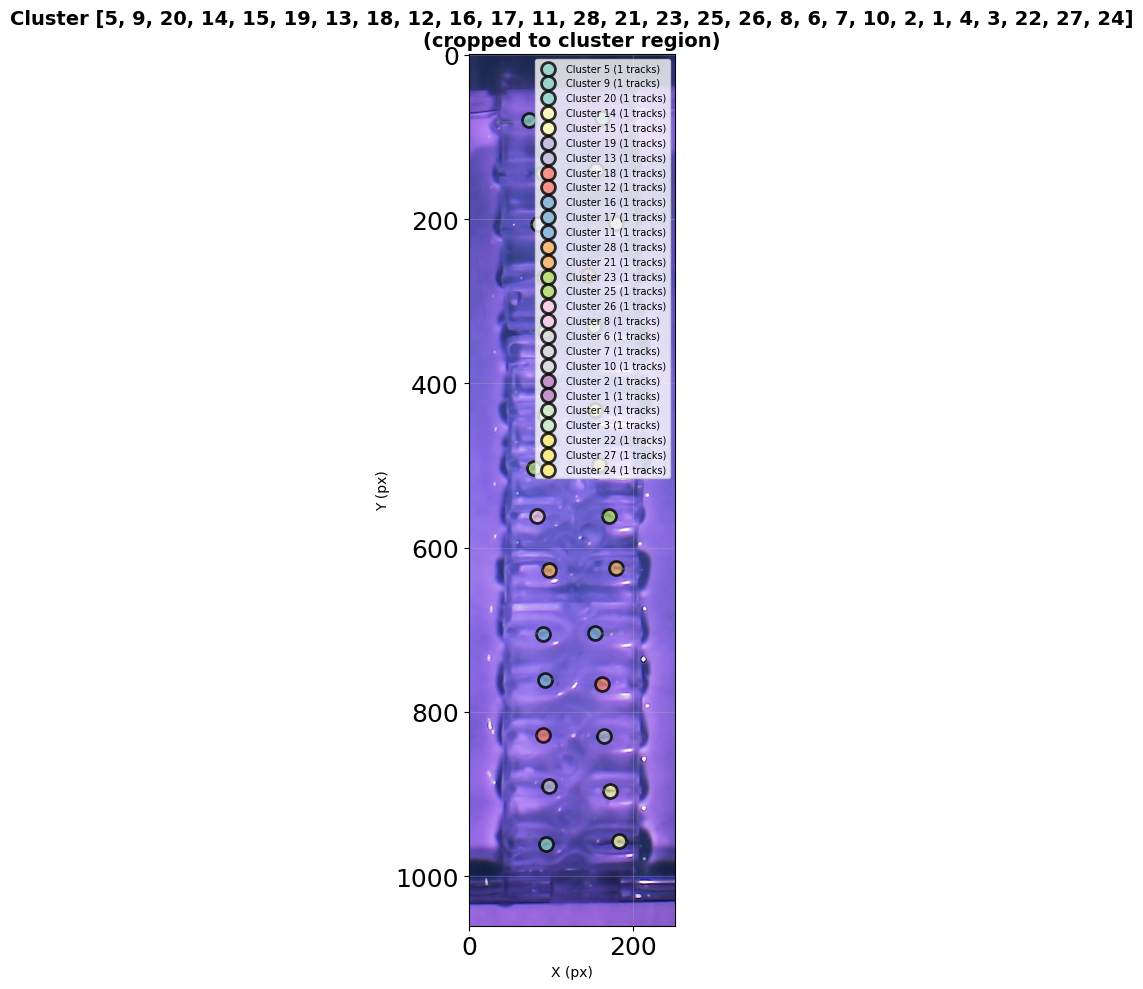

--- author output from derived cell 16: # ============================================


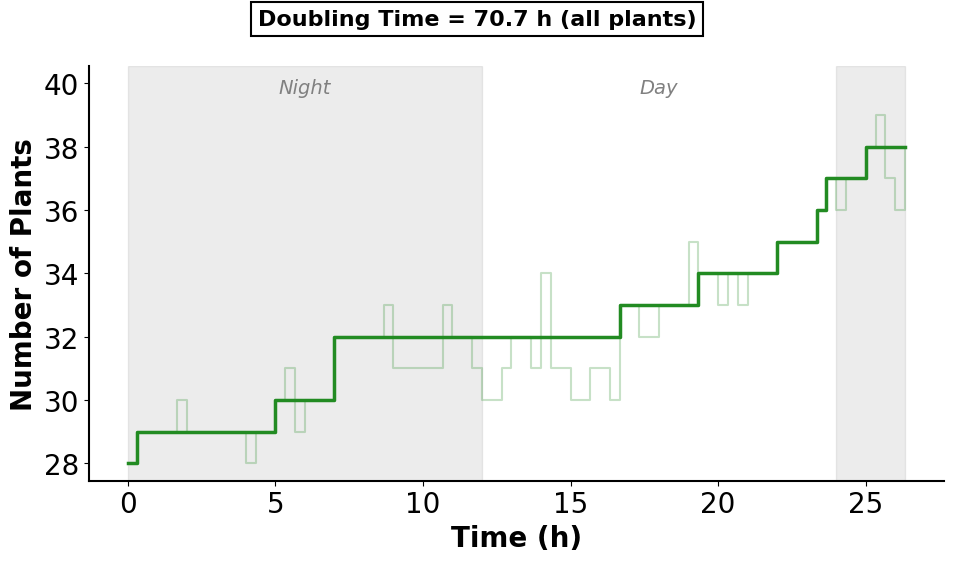

--- author output from derived cell 17: # ============================================


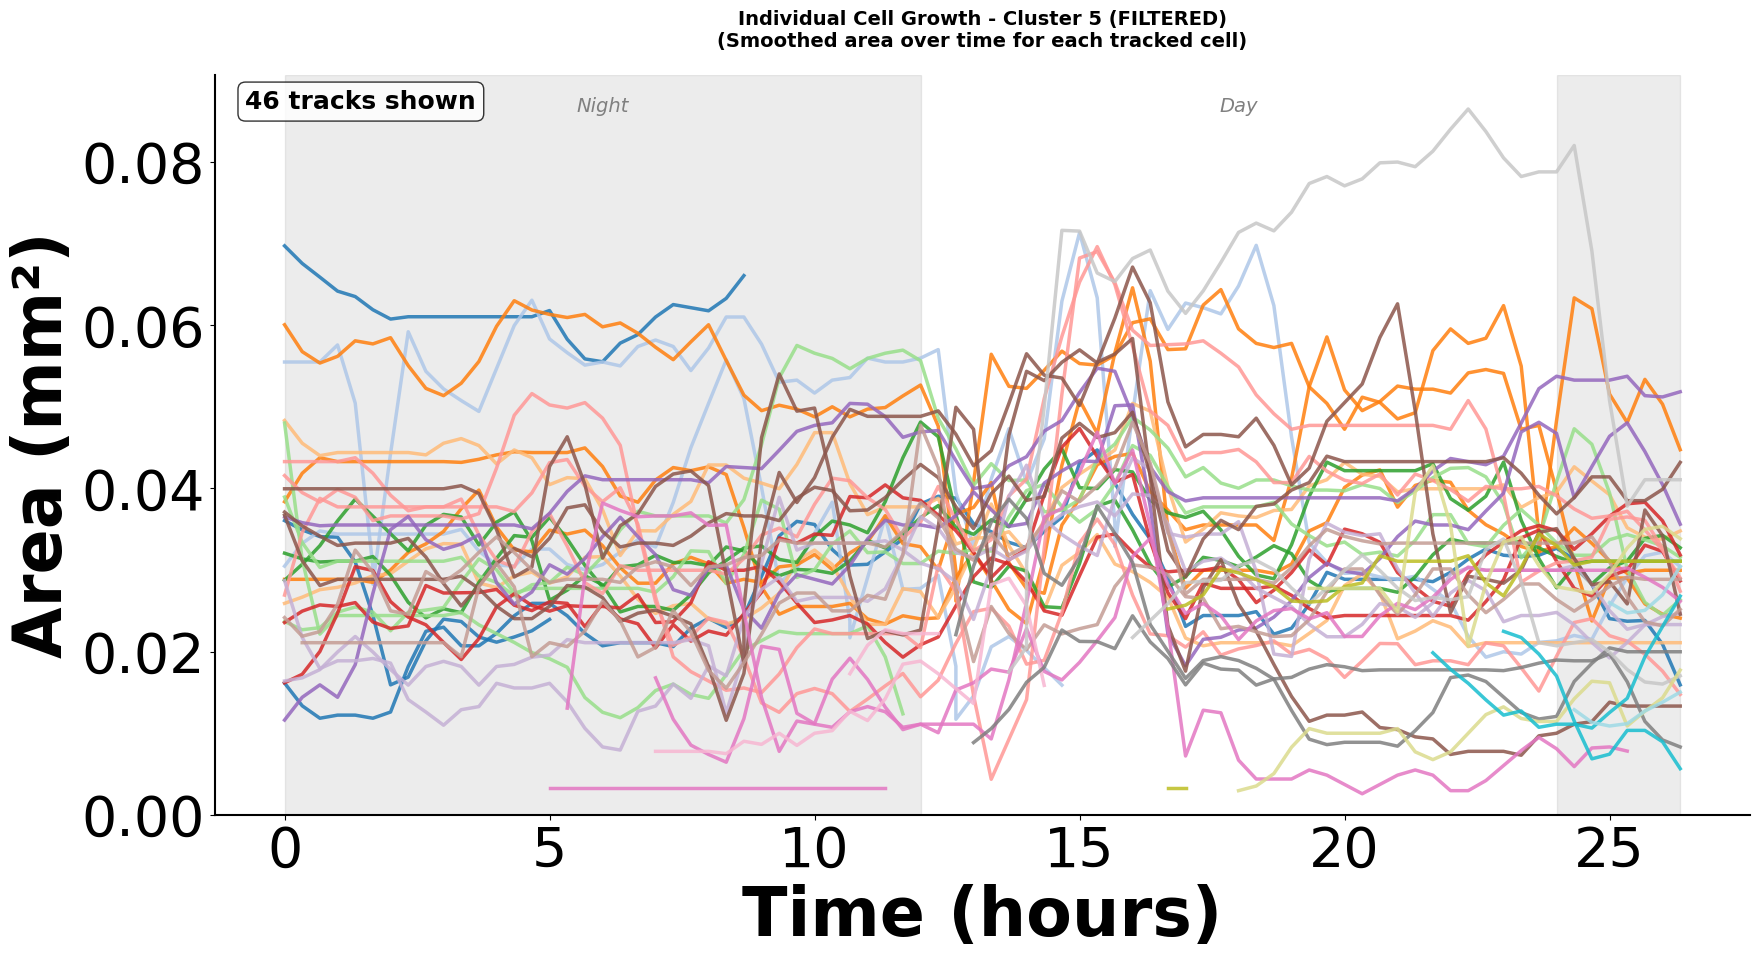

--- author output from derived cell 18: # ============================================


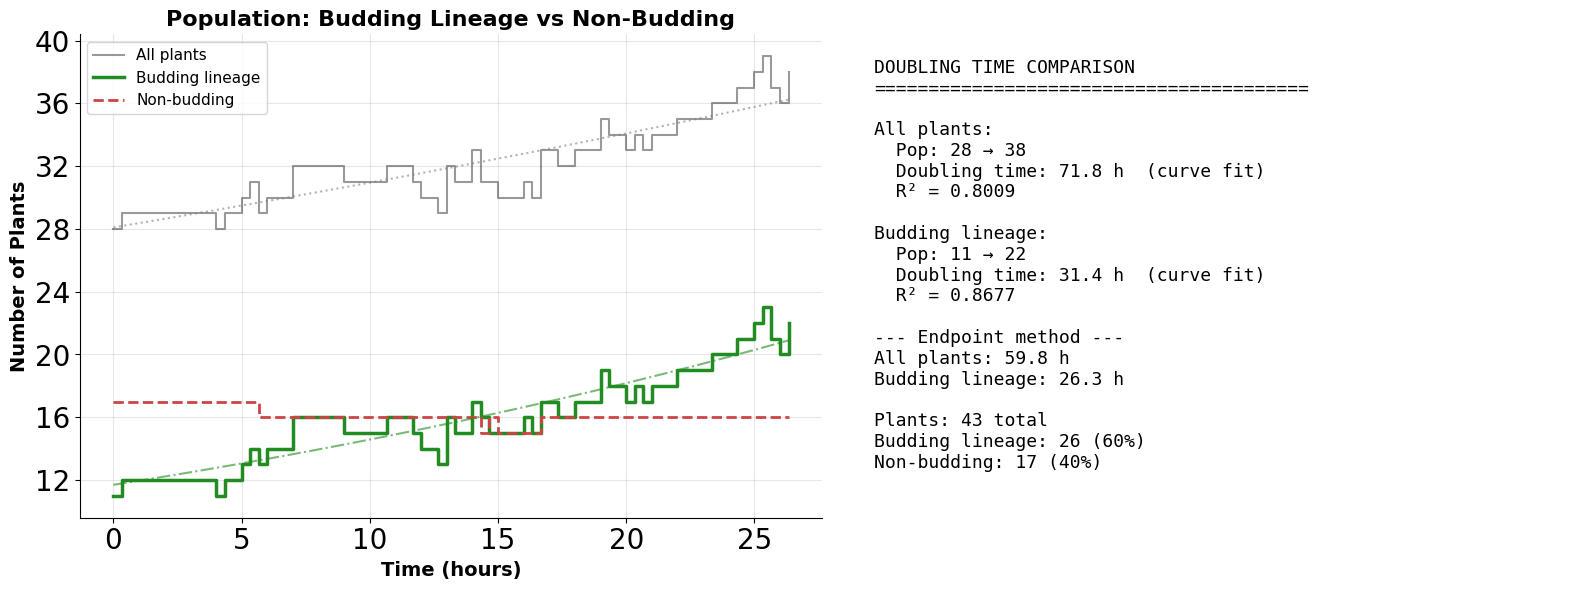

--- author output from derived cell 19: # ============================================


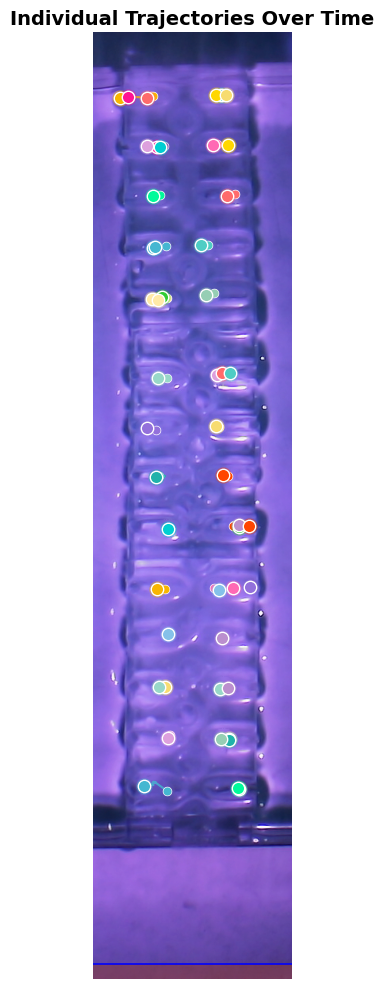

--- author output from derived cell 20: # ============================================


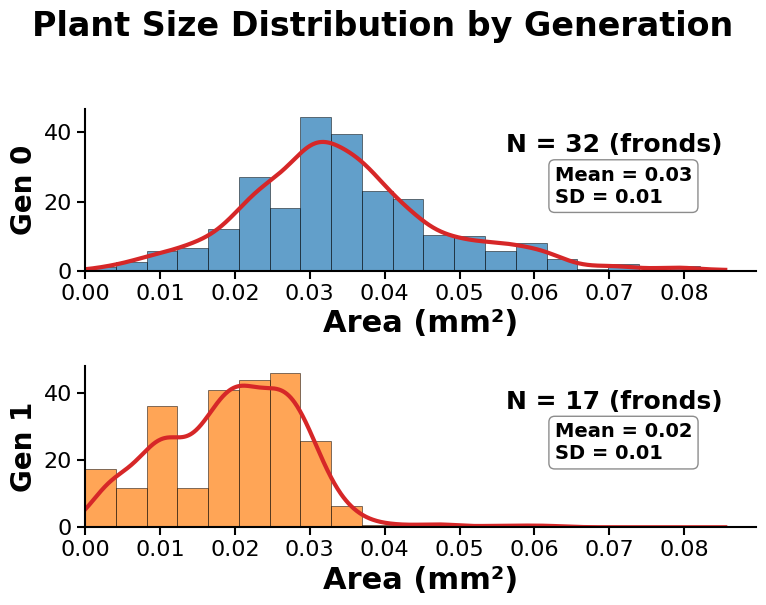

In [ ]:
import base64
from IPython.display import Image as IPyImage, display

pngs = []
for ci, cell in enumerate(exec_nb["cells"]):
    for oi, out in enumerate(cell.get("outputs", [])):
        data = (out.get("data") or {})
        if "image/png" in data:
            pngs.append((ci, cell, data["image/png"]))
print(f"{len(pngs)} PNG outputs from author cells")
for ci, cell, b64 in pngs:
    first = ("".join(cell["source"])).strip().splitlines()[0][:70]
    print(f"--- author output from derived cell {ci}: {first}")
    display(IPyImage(data=base64.b64decode(b64)))

### 10. Tracking / lineage result table (from the authors' CSV exports)

Loads `unified_tracking_data.csv` and `lineage_data.csv` written by author cell 33, prints run-level counts (frames, detections, tracks, lineage events, generations, per-track area statistics in mm² using the authors' calibration) and a small sample table. The full CSV stays on the Colab VM and can be downloaded from the file browser. 著者セルが出力した CSV から結果表を作成します。

In [ ]:
import pandas as pd
OUTDIR = PA / "paper_analysis_output" / "microfluidics"
utd = pd.read_csv(OUTDIR / "unified_tracking_data.csv")
lin = pd.read_csv(OUTDIR / "lineage_data.csv")

summary = {
    "frames": int(utd["frame"].nunique()),
    "detections": len(utd),
    "unique track_ids": int(utd["track_id"].nunique()),
    "lineage rows": len(lin),
    "hours covered": float(utd["frame"].max() * 20 / 60),
    "mean frond area (mm2)": round(float(utd["area_mm2"].mean()), 4),
    "max frond area (mm2)": round(float(utd["area_mm2"].max()), 4),
}
for k, v in summary.items(): print(f"  {k:24s}: {v}")
if len(lin): print("\nlineage sample:\n", lin.head(5).to_string(index=False))
print("\nunified_tracking_data sample:")
print(utd[["frame", "track_id", "area_pixels", "centroid_x", "centroid_y", "area_mm2"]].head(8).to_string(index=False))
utd.head(2000).to_csv("/content/deepweed_unified_tracking_sample.csv", index=False)
print("\nsample CSV export: /content/deepweed_unified_tracking_sample.csv")

  frames                  : 80
  detections              : 2569
  unique track_ids        : 49
  lineage rows            : 14
  hours covered           : 26.333333333333332
  mean frond area (mm2)   : 0.0324
  max frond area (mm2)    : 0.0855

lineage sample:
  parent_id  child_id  division_frame  distance  parent_canonical  child_canonical
      14.0      29.0             1.0  7.967926                14               29
      12.0      32.0            15.0  7.338158                12               32
      18.0      34.0            21.0  8.457081                18               34
      19.0      35.0            21.0  6.620909                19               35
      25.0      39.0            32.0  7.725573                25               39

unified_tracking_data sample:
 frame  track_id  area_pixels  centroid_x  centroid_y  area_mm2
     0         1         32.0   73.187500   79.750000   0.03552
     1         1         32.0   73.187500   79.750000   0.03552
     2         1        

## Interpretation and validation record

* **Part A** re-runs the authors' own evaluation script and published weights on the authors' published independent test set. Agreement with the paper-reported Dice/IoU/recall/precision (§2.2.3) supports that the published checkpoint and data are the ones behind the reported numbers; deviations on the order of a few thousandths are expected from library-version/hardware differences and from any difference in how many image/mask pairs ship in the zip. This is a plausibility check of one example, not a re-verification of the paper's statistics.
* **Part B** runs the authors' notebook code verbatim (pinned MD5) in microfluidics mode on the first 80 frames (≈26.7 h). Expect persistent frond identities across frames, plausible population counts, per-frond growth trajectories, and — if a budding event occurred in the window — lineage rows and generation assignments. With only 26.7 h (duckweed doubling time 24–72 h) the number of division events can be small; the paper's lineage statistics come from much longer experiments (e.g. a 338-frame, 4.7-day run, §3).
* The `area_mm²` values use the authors' hard-coded calibration from notebook cell 29 (0.00111 mm²/px).
* **日本語:** Part A は著者の評価スクリプトと公開重みを公開テストセットでそのまま実行し、論文記載値と比較しました。Part B は著者ノートブック（MD5 固定）のセルをそのまま実行したものです。26.7 時間の窓では分裂イベントは少ない場合があります。単一サンプルの実行であり、論文のデータセット全体の精度主張の検証ではありません。

**References**
1. Deepweed paper: DOI 10.1093/bioinformatics/btag779 (Bioinformatics 42(10), 2026; open-access PMC13713196, CC BY).
2. Code: https://github.com/SamOliveiraLab/Deepweed @ `7d644429035b15bcf65126ae14363b04e099f0d6`, MIT.
3. Weights + author notebook: Zenodo 22880627 (v1.1.1), MIT.
4. Datasets: Zenodo 21881225, CC BY 4.0.
5. PhenoPaper investigation p-b0f122af914788373557116b16d28981-20261128T000009Z-1244010 was used as prior research guidance; all parameters above were re-verified against the pinned primary sources.